# 13 · Visualisation: Hands-on Tutorial

In topic 12 we cleaned the shop data and answered questions with **tables**. Now we turn those answers into **charts**, using:

- **Matplotlib**: the foundation. It can draw anything, and you control every detail.
- **Seaborn**: built on Matplotlib. It makes common statistical charts from a DataFrame in one line.

Read the concepts in [README.md](README.md). All the charts below are saved in the notebook, so they show on GitHub.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import chart_style as cs   # our shared colours and style (see chart_style.py)

cs.apply()

sales = pd.read_csv("../12_pandas/data/sales_clean.csv", parse_dates=["order_date"])
sales["month"] = sales["order_date"].dt.to_period("M").dt.to_timestamp()
sales.head(3)

,order_id,order_date,customer,city,product_id,quantity,payment_method,product,category,price,revenue,month,weekday,order_size,is_big_order
0,1001,2026-06-25,Dev,Pune,P07,3,UPI,Coffee Mug,Home,349,1047,2026-06-01,Thursday,Medium,No
1,1002,2026-01-23,Priya,Delhi,P12,1,UPI,Denim Jacket,Clothing,2499,2499,2026-01-01,Friday,Large,No
2,1003,2026-02-19,Isha,Mumbai,P04,1,UPI,Python Crash Course,Books,899,899,2026-02-01,Thursday,Medium,No


## 1. Why visualise? The same statistics, four different stories

These four small datasets (**Anscombe's quartet**, from 1973) have almost the **same mean, variance and correlation**. A table of statistics says they're identical.

In [2]:
x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
quartet = {
    "I":   (x, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  (x, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (x, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
            [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
pd.DataFrame({
    name: {"mean x": np.mean(xs), "mean y": np.mean(ys),
           "var y": np.var(ys, ddof=1), "correlation": np.corrcoef(xs, ys)[0, 1]}
    for name, (xs, ys) in quartet.items()
}).round(2)

,I,II,III,IV
mean x,9.00,9.00,9.00,9.00
mean y,7.50,7.50,7.50,7.50
var y,4.13,4.13,4.12,4.12
correlation,0.82,0.82,0.82,0.82


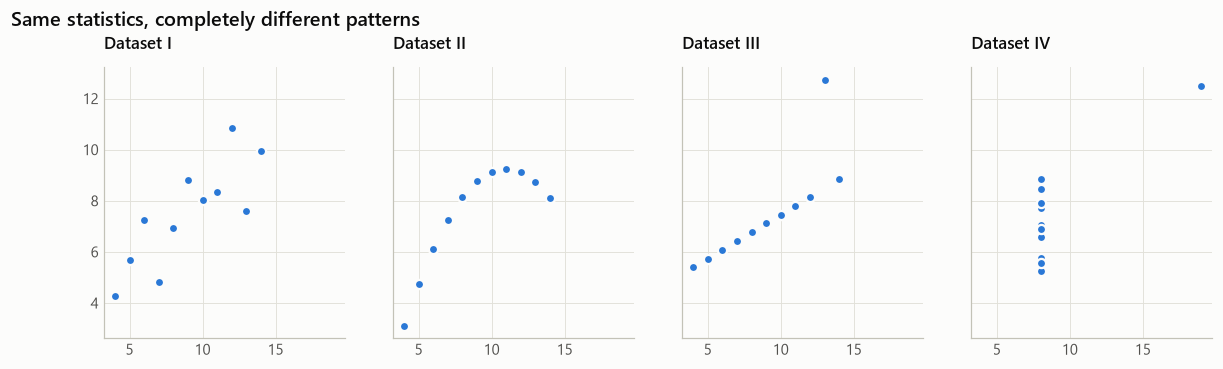

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharex=True, sharey=True)
for ax, (name, (xs, ys)) in zip(axes, quartet.items()):
    ax.scatter(xs, ys, color=cs.PRIMARY, s=36, edgecolor=cs.SURFACE, linewidth=1.5, zorder=3)
    ax.set_title(f"Dataset {name}", fontsize=11)
fig.suptitle("Same statistics, completely different patterns", x=0.06, ha="left",
             fontsize=13, fontweight="semibold", y=1.04)
plt.show()

One is a straight-line trend, one is a curve, one has a single outlier, and one is driven by a single point. **Always plot your data before trusting summary numbers.**

## 2. Matplotlib basics: Figure and Axes

Matplotlib has two layers:
- a **Figure** is the whole image (the canvas)
- an **Axes** is one chart inside it, with its own x-axis, y-axis and title

Always start with `fig, ax = plt.subplots()`. Then you call methods on `ax`. This is the *object-oriented* style, and it scales to multi-chart figures.

First, here's a chart with Matplotlib's **default** look:

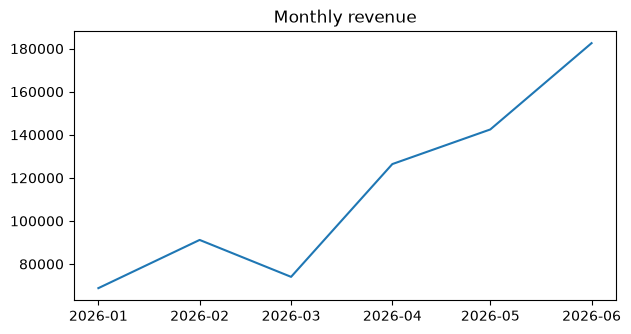

In [4]:
monthly = sales.groupby("month")["revenue"].sum()

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(monthly.index, monthly.values)
    ax.set_title("Monthly revenue")
    plt.show()

It works, but it's hard to read: the y-axis shows raw numbers like `175000`, the date labels are crowded, and there's no message.

## 3. Line chart: change over time

The same data, made clear:
- the **title states the takeaway**, and the subtitle says what is measured
- readable `₹` axis labels
- markers on each month, and a **label on the last point** only (not on every point)
- the y-axis starts at **0**, so the growth isn't exaggerated

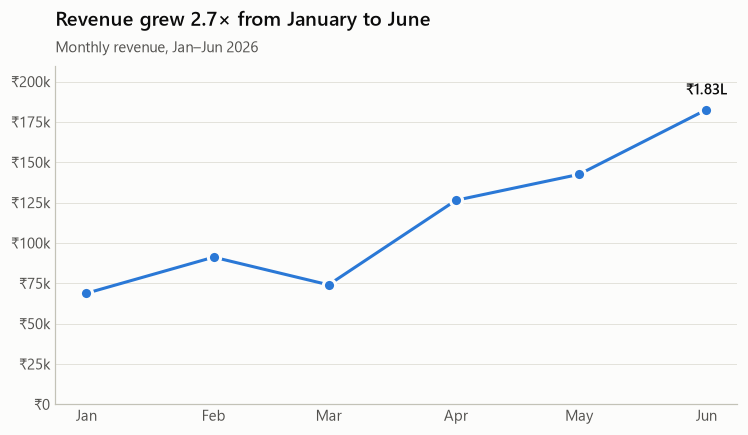

In [5]:
growth = monthly.iloc[-1] / monthly.iloc[0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly.values, color=cs.PRIMARY, marker="o",
        markeredgecolor=cs.SURFACE, markeredgewidth=2, markersize=8)
ax.set_ylim(0, monthly.max() * 1.15)
ax.yaxis.set_major_formatter(cs.RUPEES)
ax.set_xticks(monthly.index, monthly.index.strftime("%b"))
cs.only_grid(ax, "y")
ax.annotate(cs.rupees(monthly.iloc[-1]), (monthly.index[-1], monthly.iloc[-1]),
            xytext=(0, 10), textcoords="offset points", ha="center", fontweight="semibold")
cs.title(ax, f"Revenue grew {growth:.1f}× from January to June", "Monthly revenue, Jan–Jun 2026")
fig.savefig("images/monthly_revenue.png")
plt.show()

## 4. Bar chart: comparing amounts

Bars are the best way to compare quantities across categories. Good habits:
- **horizontal** bars when the labels are words, so they're easy to read
- **sorted** from biggest to smallest
- **one colour**: this is one measure (revenue), so different colours would add nothing
- the value at the end of each bar, so you don't need gridlines

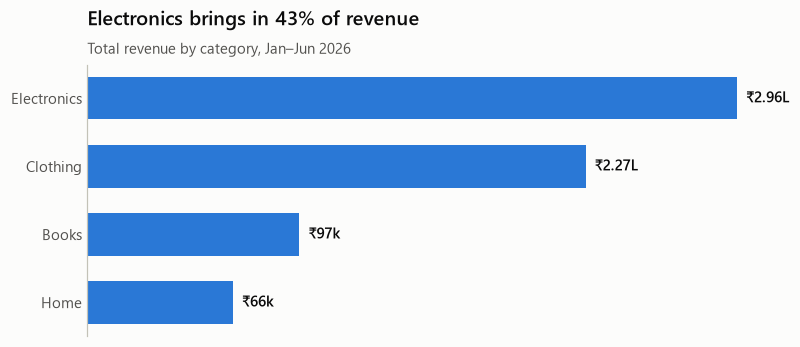

In [6]:
by_category = sales.groupby("category")["revenue"].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(by_category.index, by_category.values, color=cs.PRIMARY, height=0.62)
ax.bar_label(bars, labels=[cs.rupees(v) for v in by_category.values], padding=6,
             color=cs.INK, fontweight="semibold")
ax.xaxis.set_visible(False)
ax.grid(False)
ax.spines["bottom"].set_visible(False)
share = by_category.max() / by_category.sum()
cs.title(ax, f"Electronics brings in {share:.0%} of revenue", "Total revenue by category, Jan–Jun 2026")
plt.show()

## 5. Several lines: comparing trends

Now each category is its **own series**, so each gets its **own colour**, and that colour stays the same in every chart (see `CATEGORY_COLORS` in `chart_style.py`).
We label each line at its end, so readers don't have to look back and forth to a legend.

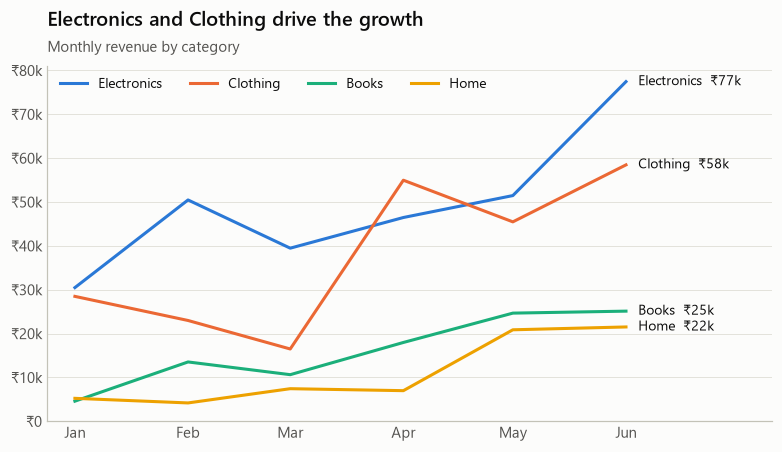

In [7]:
by_month_cat = sales.pivot_table(index="month", columns="category", values="revenue", aggfunc="sum")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for category in ["Electronics", "Clothing", "Books", "Home"]:
    series = by_month_cat[category]
    ax.plot(series.index, series.values, color=cs.CATEGORY_COLORS[category], label=category)
    ax.annotate(f"{category}  {cs.rupees(series.iloc[-1])}", (series.index[-1], series.iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=cs.INK, fontsize=9)
ax.set_ylim(0)
ax.yaxis.set_major_formatter(cs.RUPEES)
ax.set_xticks(by_month_cat.index, by_month_cat.index.strftime("%b"))
ax.set_xlim(right=by_month_cat.index[-1] + pd.Timedelta(days=40))  # room for the end labels
cs.only_grid(ax, "y")
ax.legend(loc="upper left", ncols=4)
cs.title(ax, "Electronics and Clothing drive the growth", "Monthly revenue by category")
fig.savefig("images/category_trends.png")
plt.show()

## 6. Seaborn: statistical charts from a DataFrame

Seaborn works directly with DataFrames: you name the **columns** and it does the grouping and maths.
The bar chart from section 4 takes one line, starting from the raw rows:

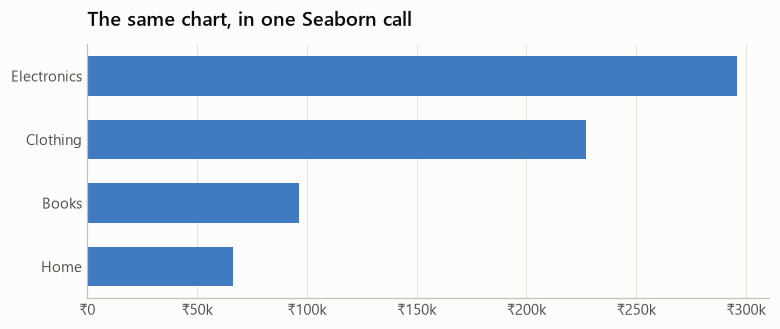

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.barplot(data=sales, y="category", x="revenue", estimator="sum", errorbar=None,
            order=by_category.index[::-1], color=cs.PRIMARY, width=0.62, ax=ax)
ax.xaxis.set_major_formatter(cs.RUPEES)
ax.set(xlabel="", ylabel="")
cs.only_grid(ax, "x")
cs.title(ax, "The same chart, in one Seaborn call")
plt.show()

## 7. Histogram: how values are distributed

A histogram splits the values into **bins** and counts how many fall in each. It shows the *shape* of the data: where most values are, how spread out they are, and whether there's a long tail.

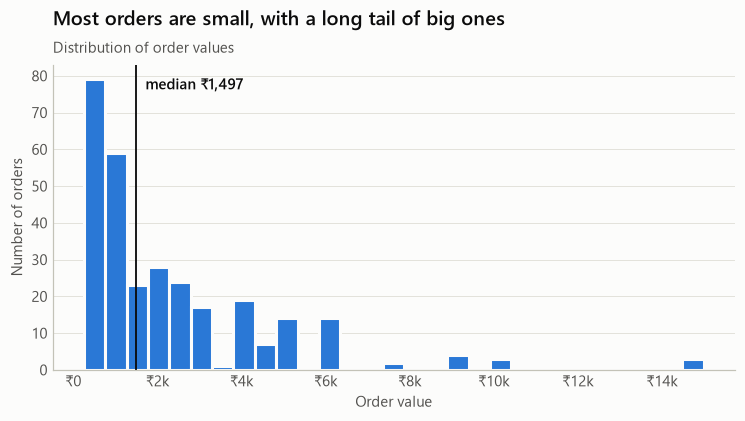

In [9]:
median = sales["revenue"].median()

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(data=sales, x="revenue", binwidth=500, color=cs.PRIMARY, edgecolor=cs.SURFACE,
             linewidth=2, alpha=1, ax=ax)
ax.axvline(median, color=cs.INK, linewidth=1.2)
ax.annotate(f"median ₹{median:,.0f}", (median, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", fontweight="semibold")
ax.xaxis.set_major_formatter(cs.RUPEES)
ax.set(xlabel="Order value", ylabel="Number of orders")
cs.only_grid(ax, "y")
cs.title(ax, "Most orders are small, with a long tail of big ones", "Distribution of order values")
plt.show()

The data is **right-skewed**: most orders are under ₹2,000, but a few go above ₹10,000. That's why the **median** is a better "typical order" here than the mean (₹2,308), which the big orders pull upwards.

## 8. Box plot: comparing distributions

A box plot summarises a distribution in five numbers. The **box** runs from the 25th to the 75th percentile (the middle 50% of orders), the **line** inside it is the median, the **whiskers** show the typical range, and the **dots** are outliers.

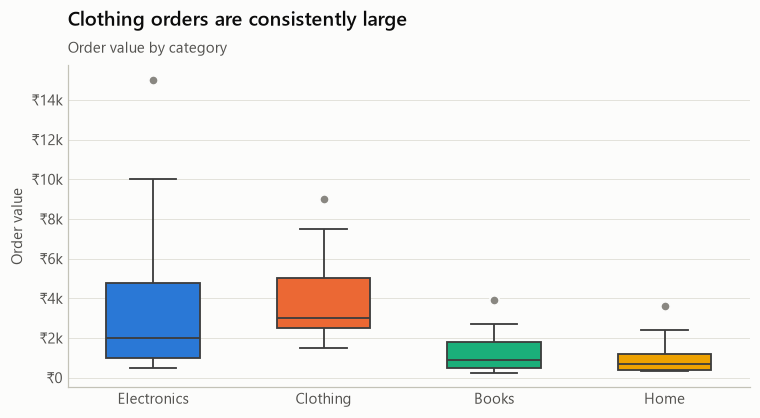

In [10]:
order = ["Electronics", "Clothing", "Books", "Home"]
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=sales, x="category", y="revenue", hue="category", order=order,
            palette=cs.CATEGORY_COLORS, saturation=1, width=0.55, linewidth=1.2, legend=False,
            flierprops={"marker": "o", "markersize": 6, "markerfacecolor": cs.MUTED,
                        "markeredgecolor": cs.SURFACE}, ax=ax)
ax.yaxis.set_major_formatter(cs.RUPEES)
ax.set(xlabel="", ylabel="Order value")
cs.only_grid(ax, "y")
cs.title(ax, "Clothing orders are consistently large", "Order value by category")
plt.show()

## 9. Scatter plot: the relationship between two numbers

Does a day with more orders also bring more revenue? Each dot is one day. `regplot` adds a fitted trend line.

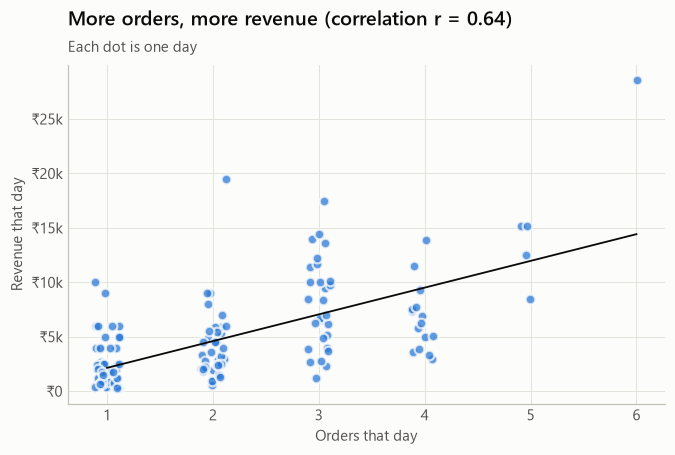

In [11]:
daily = sales.groupby("order_date").agg(orders=("order_id", "count"), revenue=("revenue", "sum"))
r = daily["orders"].corr(daily["revenue"])

fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=daily, x="orders", y="revenue", ci=None, ax=ax,
            x_jitter=0.12, color=cs.PRIMARY,
            scatter_kws={"s": 40, "alpha": 0.75, "edgecolor": cs.SURFACE, "linewidths": 1.5},
            line_kws={"color": cs.INK, "linewidth": 1.2})
ax.yaxis.set_major_formatter(cs.RUPEES)
ax.set(xlabel="Orders that day", ylabel="Revenue that day")
cs.title(ax, f"More orders, more revenue (correlation r = {r:.2f})", "Each dot is one day")
plt.show()

The correlation `r` runs from -1 to +1. Here it's positive and moderate: busier days earn more, but one big order can matter more than several small ones.

## 10. Heatmap: a table you can see

A heatmap colours each cell of a table by its value. For magnitude we use **one hue from light to dark** (never a rainbow). We also write the numbers in the cells, so nobody has to guess a value from the shade.

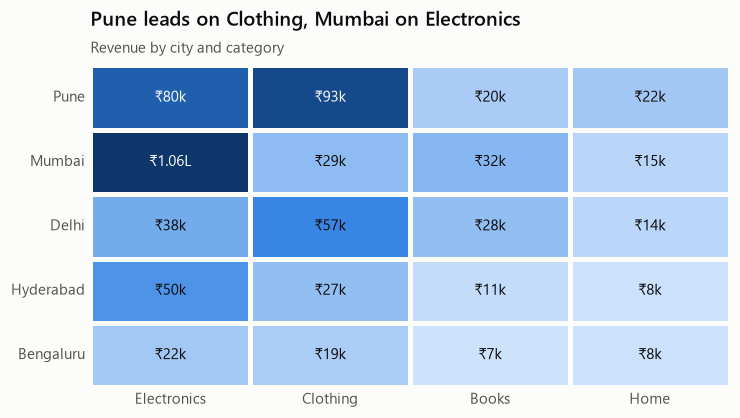

In [12]:
grid = sales.pivot_table(index="city", columns="category", values="revenue", aggfunc="sum")
grid = grid.loc[grid.sum(axis=1).sort_values(ascending=False).index, order]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.heatmap(grid, cmap=cs.BLUES, annot=grid.map(cs.rupees), fmt="", linewidths=2,
            linecolor=cs.SURFACE, cbar=False, annot_kws={"fontsize": 9.5}, ax=ax)
cs.contrast_text(ax, grid.values)   # white text only where the cell is dark enough
ax.set(xlabel="", ylabel="")
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
cs.title(ax, "Pune leads on Clothing, Mumbai on Electronics", "Revenue by city and category")
fig.savefig("images/city_heatmap.png")
plt.show()

## 11. Pie or bar? Choosing the right form

Pie charts are popular, but people are bad at comparing angles. Here are the payment methods both ways:

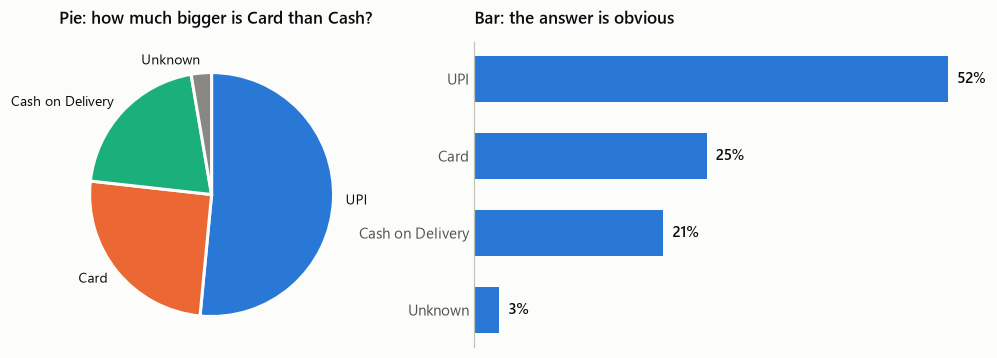

In [13]:
payments = sales["payment_method"].value_counts(normalize=True) * 100
colors = [cs.SLOTS[0], cs.SLOTS[1], cs.SLOTS[2], cs.MUTED]   # "Unknown" in grey: it's not a real method

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
left.pie(payments.values, labels=payments.index, colors=colors, startangle=90, counterclock=False,
         wedgeprops={"linewidth": 2, "edgecolor": cs.SURFACE}, textprops={"fontsize": 9})
left.set_title("Pie: how much bigger is Card than Cash?", fontsize=11)

ordered = payments.sort_values()
bars = right.barh(ordered.index, ordered.values, color=cs.PRIMARY, height=0.6)
right.bar_label(bars, labels=[f"{v:.0f}%" for v in ordered.values], padding=6, fontweight="semibold")
right.xaxis.set_visible(False)
right.grid(False)
right.spines["bottom"].set_visible(False)
right.set_title("Bar: the answer is obvious", fontsize=11)
plt.show()

Use a pie only for a **part-to-whole** view with **few slices** (6 at most) whose sizes are clearly different. When you need to compare, use a bar.

## 12. Many charts in one figure: a mini dashboard

`plt.subplots(rows, cols)` creates a grid of Axes. Here are four charts that tell the shop's story at a glance.

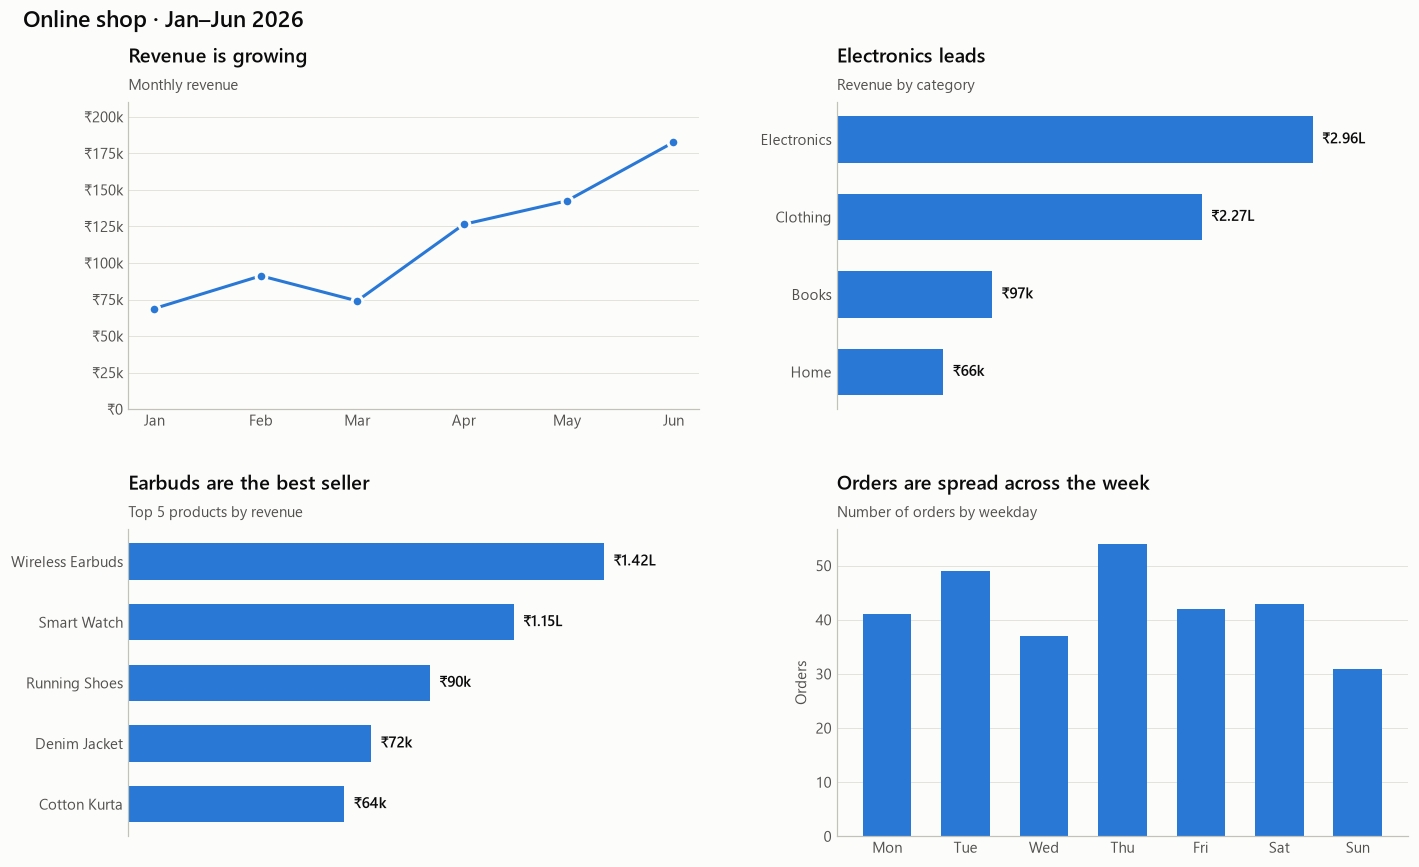

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
(a, b), (c, d) = axes

# A: trend
a.plot(monthly.index, monthly.values, color=cs.PRIMARY, marker="o",
       markeredgecolor=cs.SURFACE, markeredgewidth=2, markersize=7)
a.set_ylim(0, monthly.max() * 1.15)
a.yaxis.set_major_formatter(cs.RUPEES)
a.set_xticks(monthly.index, monthly.index.strftime("%b"))
cs.only_grid(a, "y")
cs.title(a, "Revenue is growing", "Monthly revenue")

# B: categories
bars = b.barh(by_category.index, by_category.values, color=cs.PRIMARY, height=0.6)
b.bar_label(bars, labels=[cs.rupees(v) for v in by_category.values], padding=6, fontweight="semibold")
b.xaxis.set_visible(False)
b.grid(False)
b.spines["bottom"].set_visible(False)
b.set_xlim(0, by_category.max() * 1.2)
cs.title(b, "Electronics leads", "Revenue by category")

# C: top products
top = sales.groupby("product")["revenue"].sum().nlargest(5).sort_values()
bars = c.barh(top.index, top.values, color=cs.PRIMARY, height=0.6)
c.bar_label(bars, labels=[cs.rupees(v) for v in top.values], padding=6, fontweight="semibold")
c.xaxis.set_visible(False)
c.grid(False)
c.spines["bottom"].set_visible(False)
c.set_xlim(0, top.max() * 1.2)
cs.title(c, "Earbuds are the best seller", "Top 5 products by revenue")

# D: weekday
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = sales["order_date"].dt.day_name().value_counts().reindex(days)
d.bar([day[:3] for day in days], weekday.values, color=cs.PRIMARY, width=0.62)
d.set_ylabel("Orders")
cs.only_grid(d, "y")
cs.title(d, "Orders are spread across the week", "Number of orders by weekday")

fig.suptitle("Online shop · Jan–Jun 2026", x=0.02, ha="left", fontsize=15, fontweight="semibold")
fig.tight_layout(h_pad=3, w_pad=4)
fig.savefig("images/dashboard.png")
plt.show()

## 13. Saving charts

```python
fig.savefig("images/chart.png", dpi=150, bbox_inches="tight")   # for reports and README files
fig.savefig("images/chart.svg")                                  # sharp at any size, for the web
```

`bbox_inches="tight"` trims the empty border. Our `chart_style.apply()` already sets both of these defaults.

## What you learned

| Question about the data | Chart | Code |
|-------------------------|-------|------|
| How does it change over time? | Line | `ax.plot` |
| Which is bigger? | Bar (sorted, horizontal for words) | `ax.barh`, `sns.barplot` |
| How are values spread? | Histogram, box plot | `sns.histplot`, `sns.boxplot` |
| Are two numbers related? | Scatter (+ trend line) | `ax.scatter`, `sns.regplot` |
| How do two categories combine? | Heatmap | `sns.heatmap` |
| What share of the whole? | Bar (or a pie with ≤ 6 clear slices) | `ax.barh`, `ax.pie` |
| Several views at once | Subplots grid | `plt.subplots(2, 2)` |

**Next:** topic 14 adds statistics: when a difference is real and when it's just chance.